# Task 1.2 - Filtering, Denoising, Edges and Frequency Domain

**Module:** FCVG101 Introduction to Computer Vision

## Objective
* Add two kinds of synthetic noise to a clean image and compare four smoothing filters (box, Gaussian, median, bilateral) with **PSNR** and **SSIM**.
* Compute image gradients (Sobel), the Laplacian and Canny edges, and see how noise affects them.
* Look at the same filters in the **frequency domain** (FFT) and implement a 2D convolution **from scratch**.

Data: `lena.jpg` (512 x 512, a clean image, so we know the ground truth and can measure the denoising quality).

## Theory (short)

**Noise models.** *Gaussian noise*: every pixel gets a small random value from N(0, sigma^2) (sensor / electronic noise). *Salt & pepper*: a few random pixels are set to 0 or 255 (dead pixels, transmission errors).

**Linear filters** replace a pixel by a weighted sum of its neighbours (convolution with a kernel): `g(x,y) = sum k(i,j) f(x+i, y+j)`. Box = all weights equal; Gaussian = weights fall off with distance. They average noise away but also blur edges.

**Median filter** (non-linear) takes the *median* of the neighbours, so an extreme value (a white/black impulse) is simply ignored. **Bilateral filter** is a Gaussian that also down-weights neighbours with a *different intensity*, so it smooths flat areas but keeps edges.

**Quality metrics.** `PSNR = 10 log10(255^2 / MSE)` in dB (higher is better). `SSIM` compares local luminance, contrast and structure (1 = identical).

**Gradients and edges.** An edge is a rapid intensity change = large gradient. Sobel estimates `Gx, Gy`; magnitude `sqrt(Gx^2 + Gy^2)`, direction `atan2(Gy, Gx)`. The Laplacian is the second derivative (zero crossings = edges, very noise sensitive). **Canny** = Gaussian blur -> gradient -> non-maximum suppression (thin edges) -> hysteresis thresholds (`high` = sure edge, `low` = kept only if connected to a sure edge).

**Frequency domain.** The Fourier transform writes the image as a sum of sinusoids. Low frequencies = smooth areas, high frequencies = edges and noise. By the convolution theorem, spatial filtering = multiplication in the frequency domain: `G(u,v) = H(u,v) F(u,v)`. A Gaussian low-pass `H = exp(-D^2 / (2 D0^2))` is the same as a spatial Gaussian blur with `sigma = N / (2 pi D0)` for an image of N pixels.

In [1]:
# --- Setup: find the project root (the folder that contains "src") and import our modules ---
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent          # walk up until we find the folder that has "src"
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.task1.results import update_results

TASK1 = ROOT / "Task1"
OUT = TASK1 / "outputs"
OUT.mkdir(exist_ok=True)
RESULTS_JSON = OUT / "task1_results.json"   # all key numbers are collected here

def show(ax, img, title="", cmap=None):
    """Show an OpenCV image (BGR or gray) on a matplotlib axis."""
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # matplotlib expects RGB
        ax.imshow(img)
    else:
        ax.imshow(img, cmap=cmap or "gray", vmin=0 if img.dtype == np.uint8 else None,
                  vmax=255 if img.dtype == np.uint8 else None)
    ax.set_title(title, fontsize=10)
    ax.axis("off")

print("Project root:", ROOT.name)

from src.task1.filtering import (
    add_gaussian_noise, add_salt_pepper_noise, apply_filter, psnr, ssim,
    convolve2d_from_scratch, sobel_gradients, laplacian, canny_edges, detect_edges,
    fft_spectrum, frequency_mask, frequency_filter,
)

lena = cv2.imread(str(TASK1 / "noise_data" / "lena.jpg"))     # BGR, clean
gray = cv2.cvtColor(lena, cv2.COLOR_BGR2GRAY)
print("lena:", lena.shape, lena.dtype)

Project root: FCVG101_Coursework


lena: (512, 512, 3) uint8


## Step 1 - Add synthetic noise
Gaussian noise with sigma = 25 grey levels and salt & pepper noise on 5 % of the pixels. A fixed seed makes the experiment reproducible. The PSNR of the noisy image is the baseline every filter must beat.

In [2]:
noisy = {
    "Gaussian noise (sigma=25)": add_gaussian_noise(lena, sigma=25, seed=0),
    "Salt & pepper (5%)": add_salt_pepper_noise(lena, amount=0.05, seed=0),
}
for name, img in noisy.items():
    print(f"{name:28s} PSNR = {psnr(lena, img):5.2f} dB   SSIM = {ssim(lena, img):.3f}")

Gaussian noise (sigma=25)    PSNR = 20.36 dB   SSIM = 0.296
Salt & pepper (5%)           PSNR = 18.21 dB   SSIM = 0.338


## Step 2 - Compare the four filters on each noise type
Settings: box 5x5, Gaussian 5x5 (sigma = 1.0), median 5x5, bilateral (d = 9, sigmaColor = 75, sigmaSpace = 75). `apply_filter(img, name, **params)` calls the matching OpenCV function. PSNR and SSIM are computed against the clean image.

In [3]:
FILTERS = {
    "box":       dict(ksize=5),
    "gaussian":  dict(ksize=5, sigma=1.0),
    "median":    dict(ksize=5),
    "bilateral": dict(d=9, sigma_color=75, sigma_space=75),
}

rows, filtered = [], {}
for noise_name, noisy_img in noisy.items():
    rows.append({"noise": noise_name, "filter": "none (noisy)", "PSNR (dB)": psnr(lena, noisy_img), "SSIM": ssim(lena, noisy_img)})
    filtered[noise_name] = {}
    for fname, params in FILTERS.items():
        out = apply_filter(noisy_img, fname, **params)
        filtered[noise_name][fname] = out
        rows.append({"noise": noise_name, "filter": fname, "PSNR (dB)": psnr(lena, out), "SSIM": ssim(lena, out)})

metrics = pd.DataFrame(rows)
metrics[["PSNR (dB)", "SSIM"]] = metrics[["PSNR (dB)", "SSIM"]].round(3)
metrics.to_csv(OUT / "filter_metrics.csv", index=False)
display(metrics)

,noise,filter,PSNR (dB),SSIM
0,Gaussian noise (sigma=25),none (noisy),20.361,0.296
1,Gaussian noise (sigma=25),box,28.190,0.730
2,Gaussian noise (sigma=25),gaussian,28.940,0.703
3,Gaussian noise (sigma=25),median,28.071,0.685
4,Gaussian noise (sigma=25),bilateral,29.099,0.703
5,Salt & pepper (5%),none (noisy),18.214,0.338
6,Salt & pepper (5%),box,27.207,0.685
7,Salt & pepper (5%),gaussian,27.204,0.647
8,Salt & pepper (5%),median,30.889,0.856
9,Salt & pepper (5%),bilateral,18.267,0.299


## Step 3 - Visual comparison
Each row = one noise type; columns = clean reference, noisy input, then the four filter outputs (PSNR in the titles). We zoom on a 160 x 160 crop of the face so that the differences are visible.

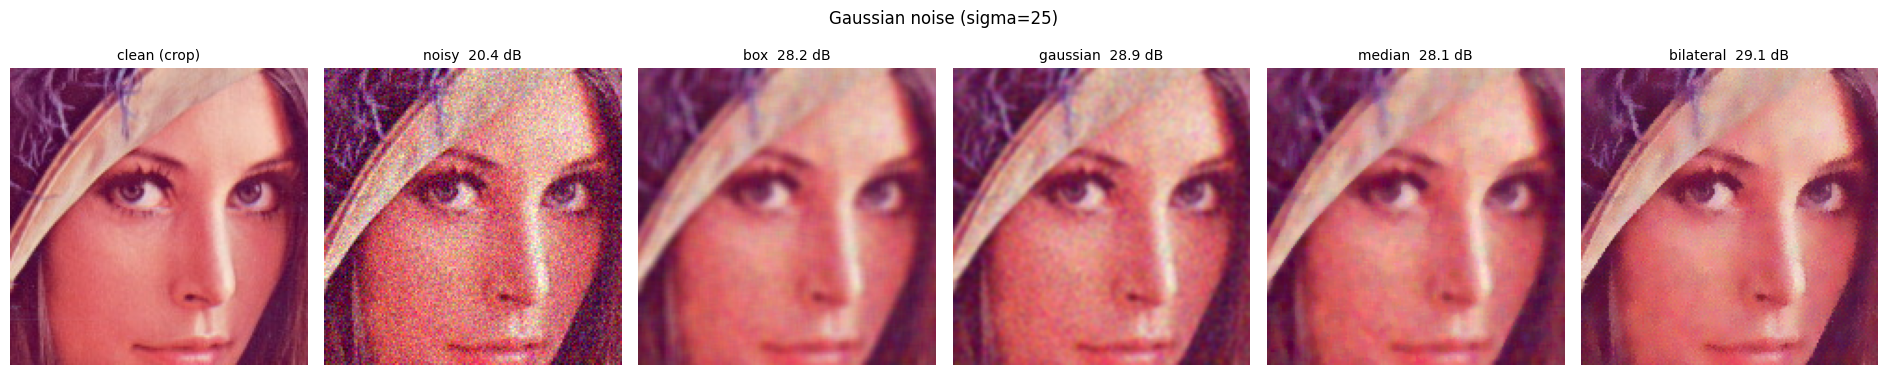

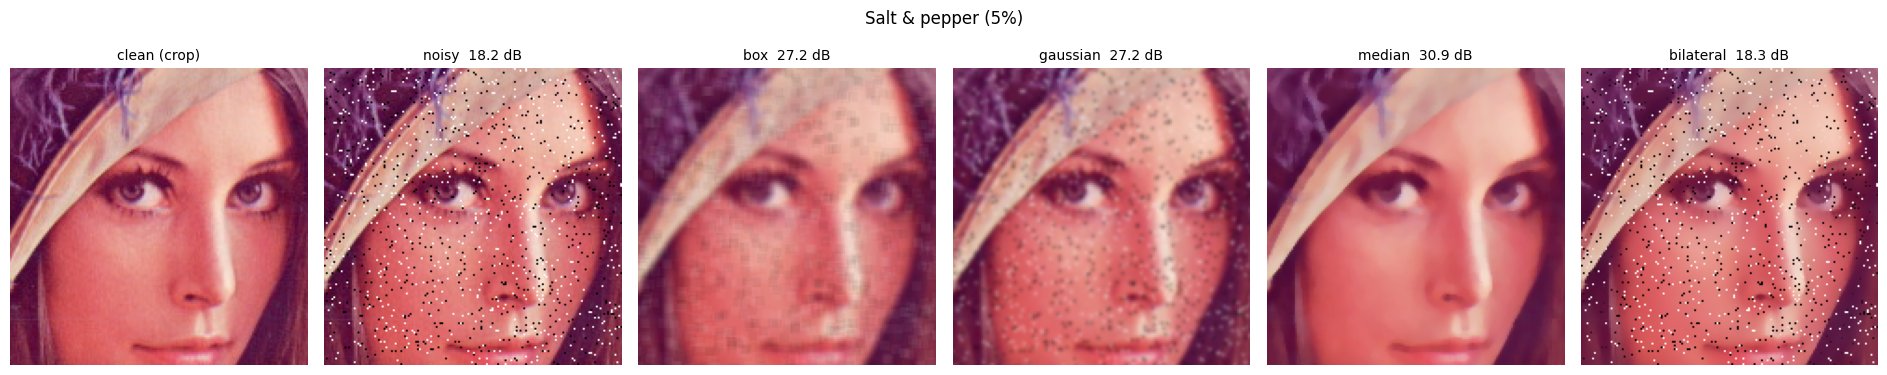

In [4]:
def crop(img, y=200, x=200, size=160):
    return img[y:y + size, x:x + size]

def grid_figure(noise_name, save_name):
    fig, axes = plt.subplots(1, 6, figsize=(19, 3.6))
    show(axes[0], crop(lena), "clean (crop)")
    show(axes[1], crop(noisy[noise_name]), f"noisy  {psnr(lena, noisy[noise_name]):.1f} dB")
    for ax, (fname, out) in zip(axes[2:], filtered[noise_name].items()):
        show(ax, crop(out), f"{fname}  {psnr(lena, out):.1f} dB")
    fig.suptitle(noise_name, y=1.03)
    plt.tight_layout()
    plt.savefig(OUT / save_name, dpi=120, bbox_inches="tight")
    plt.show()

grid_figure("Gaussian noise (sigma=25)", "denoise_gaussian_noise.png")
grid_figure("Salt & pepper (5%)", "denoise_saltpepper.png")

## Step 4 - Which filter wins?
We pick the best filter per noise type by PSNR (SSIM is shown too, they usually agree).

In [5]:
best = {}
for noise_name in noisy:
    sub = metrics[(metrics.noise == noise_name) & (metrics["filter"] != "none (noisy)")]
    row = sub.loc[sub["PSNR (dB)"].idxmax()]
    best[noise_name] = {"filter": row["filter"], "PSNR_dB": float(row["PSNR (dB)"]), "SSIM": float(row["SSIM"]),
                        "best_by_SSIM": sub.loc[sub["SSIM"].idxmax(), "filter"]}
    print(f"{noise_name:28s} best by PSNR = {row['filter']:9s} ({row['PSNR (dB)']:.2f} dB, SSIM {row['SSIM']:.3f}); best by SSIM = {best[noise_name]['best_by_SSIM']}")

Gaussian noise (sigma=25)    best by PSNR = bilateral (29.10 dB, SSIM 0.703); best by SSIM = box
Salt & pepper (5%)           best by PSNR = median    (30.89 dB, SSIM 0.856); best by SSIM = median


## Step 5 - Gradients: Sobel and Laplacian
`sobel_gradients` returns `Gx`, `Gy`, the magnitude and the direction (computed in 32-bit float because the derivatives are negative on one side of an edge). `laplacian` gives the absolute second derivative.

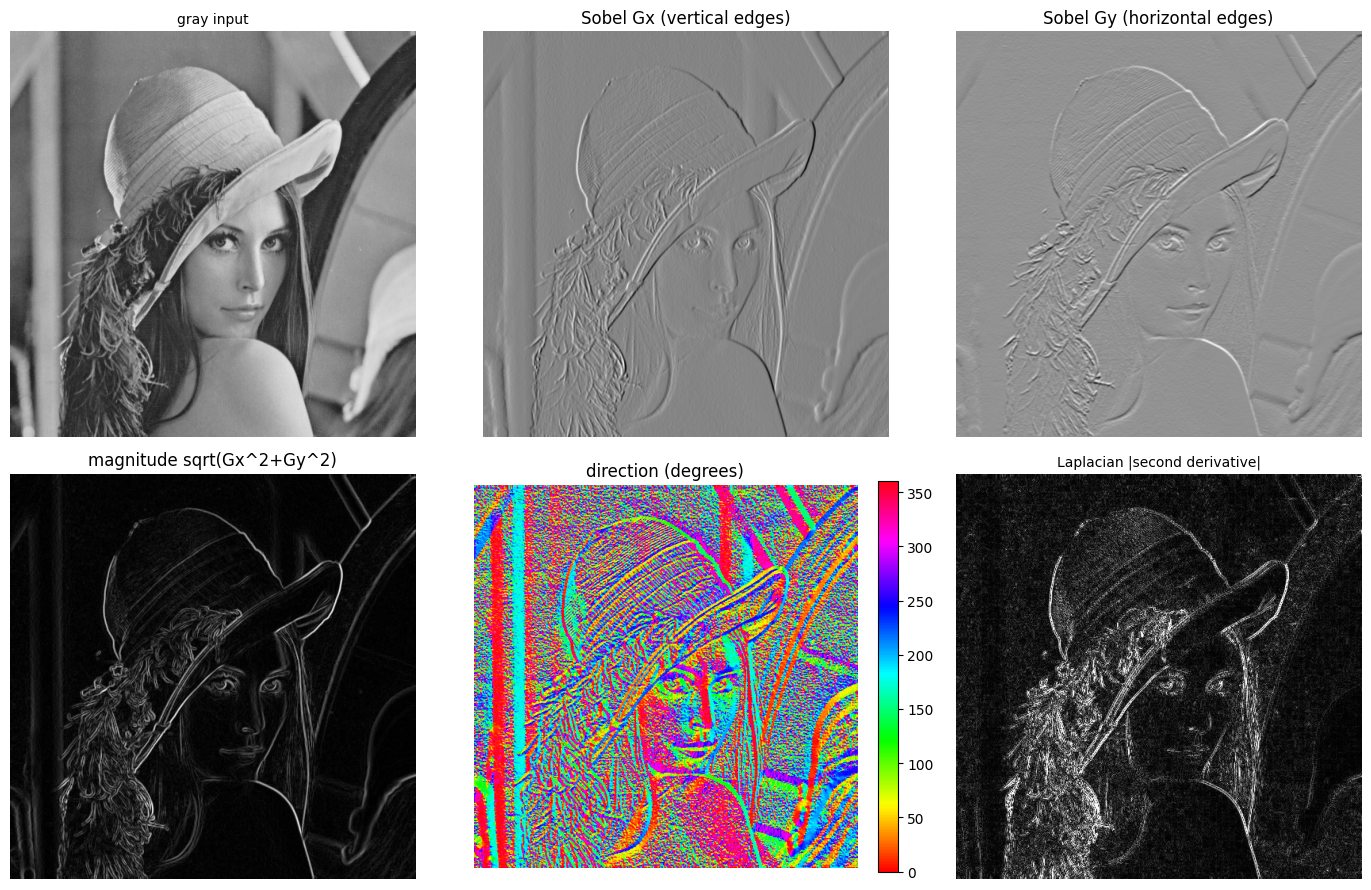

Gradient magnitude: min 0, max 713, mean 49.1


In [6]:
g = sobel_gradients(gray, ksize=3)
lap = laplacian(gray, ksize=3)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
show(axes[0, 0], gray, "gray input")
axes[0, 1].imshow(g["gx"], cmap="gray");  axes[0, 1].set_title("Sobel Gx (vertical edges)");   axes[0, 1].axis("off")
axes[0, 2].imshow(g["gy"], cmap="gray");  axes[0, 2].set_title("Sobel Gy (horizontal edges)"); axes[0, 2].axis("off")
axes[1, 0].imshow(g["magnitude"], cmap="gray"); axes[1, 0].set_title("magnitude sqrt(Gx^2+Gy^2)"); axes[1, 0].axis("off")
im = axes[1, 1].imshow(g["direction"], cmap="hsv"); axes[1, 1].set_title("direction (degrees)"); axes[1, 1].axis("off")
plt.colorbar(im, ax=axes[1, 1], fraction=0.046)
show(axes[1, 2], lap, "Laplacian |second derivative|")
plt.tight_layout()
plt.savefig(OUT / "gradients.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"Gradient magnitude: min {g['magnitude'].min():.0f}, max {g['magnitude'].max():.0f}, mean {g['magnitude'].mean():.1f}")

## Step 6 - Canny edges: thresholds and the role of blurring
Top row: three `(low, high)` threshold pairs on the clean image (lower thresholds -> more, weaker edges). Bottom row: the Gaussian-noise image with no blur and with Gaussian blur before Canny. Without blur the noise creates thousands of false edges.

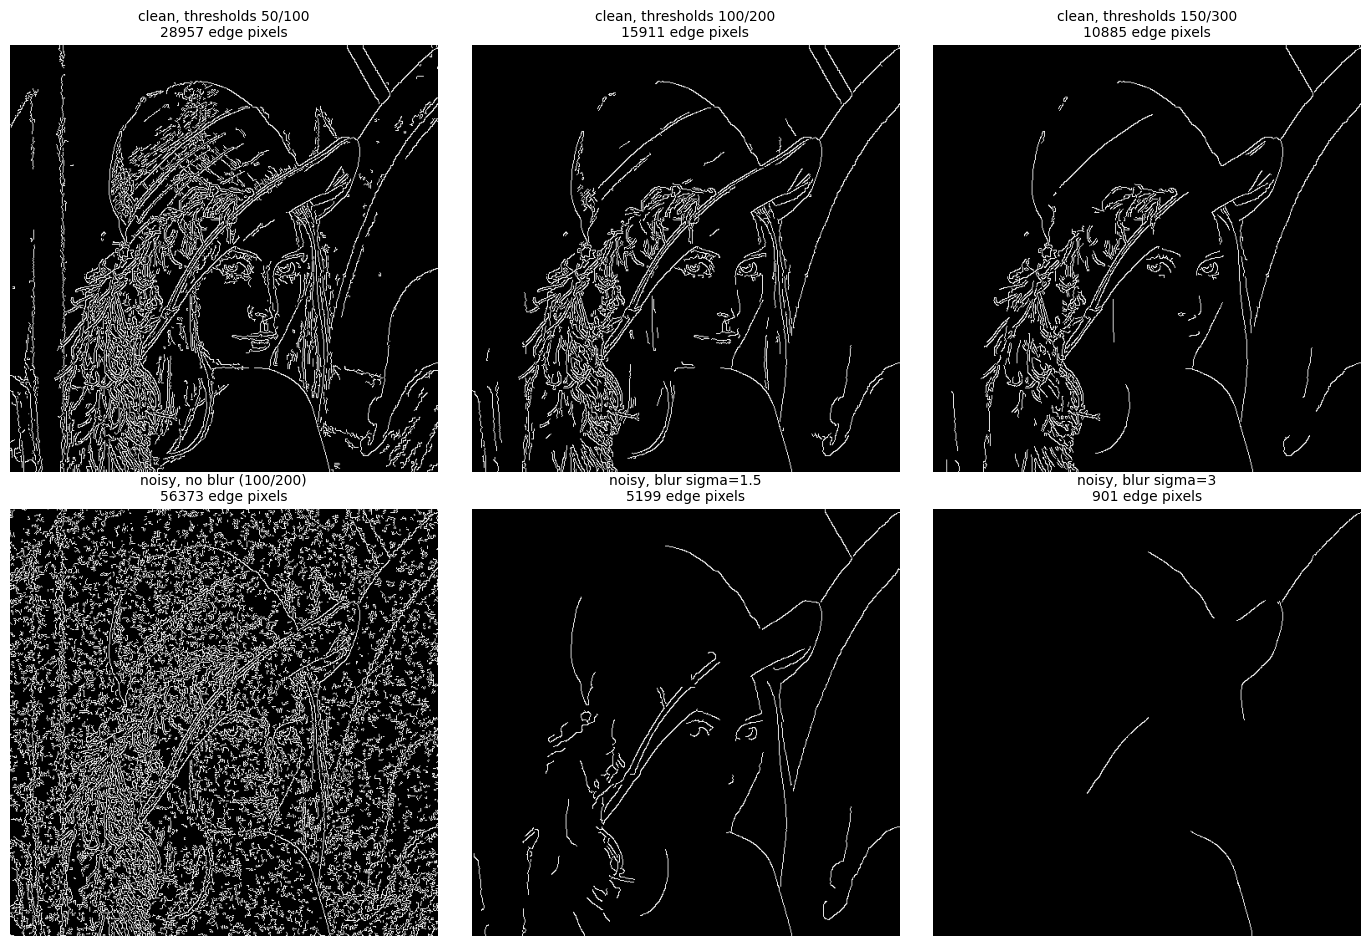

sobel -> (512, 512)
laplacian -> (512, 512)
canny -> (512, 512)


In [7]:
noisy_gray = cv2.cvtColor(noisy["Gaussian noise (sigma=25)"], cv2.COLOR_BGR2GRAY)

panels = [
    ("clean, thresholds 50/100",   canny_edges(gray, 50, 100)),
    ("clean, thresholds 100/200",  canny_edges(gray, 100, 200)),
    ("clean, thresholds 150/300",  canny_edges(gray, 150, 300)),
    ("noisy, no blur (100/200)",   canny_edges(noisy_gray, 100, 200)),
    ("noisy, blur sigma=1.5",      canny_edges(noisy_gray, 100, 200, blur_sigma=1.5)),
    ("noisy, blur sigma=3",        canny_edges(noisy_gray, 100, 200, blur_sigma=3.0)),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 9.5))
canny_counts = {}
for ax, (title, edges) in zip(axes.ravel(), panels):
    n_edge = int((edges > 0).sum())
    canny_counts[title] = n_edge
    show(ax, edges, f"{title}\n{n_edge} edge pixels")
plt.tight_layout()
plt.savefig(OUT / "canny.png", dpi=120, bbox_inches="tight")
plt.show()

# generic dispatcher (used by the Gradio app): detect_edges(img, method)
for m in ["sobel", "laplacian", "canny"]:
    print(m, "->", detect_edges(lena, m).shape)

## Step 7 - Convolution from scratch
`convolve2d_from_scratch` slides a kernel over the image using plain numpy (mirror padding at the border; for every kernel weight it adds `weight x shifted image`). We compare it with `cv2.filter2D` for a box, a Gaussian and a Sobel kernel. OpenCV rounds the result back to uint8, so we compare against the float version of `cv2.filter2D` first (exact check) and against the uint8 output (a difference of at most 1 grey level is only rounding: OpenCV uses fixed-point arithmetic internally).

In [8]:
gauss1d = cv2.getGaussianKernel(5, 1.0)
kernels = {
    "box 5x5":      np.ones((5, 5)) / 25.0,
    "gaussian 5x5": gauss1d @ gauss1d.T,
    "sobel x 3x3":  np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64),
}
conv_rows = []
for name, k in kernels.items():
    ours = convolve2d_from_scratch(gray, k)
    ref_float = cv2.filter2D(gray.astype(np.float64), -1, k)       # same maths, float output
    ref_uint8 = cv2.filter2D(gray, -1, k)                          # OpenCV's usual 8-bit output
    conv_rows.append({"kernel": name,
                      "max |ours - filter2D (float)|": np.abs(ours - ref_float).max(),
                      "max |round(ours) - filter2D (uint8)|": np.abs(np.clip(np.round(ours), 0, 255) - ref_uint8).max()})
conv_table = pd.DataFrame(conv_rows)
display(conv_table)

,kernel,max |ours - filter2D (float)|,max |round(ours) - filter2D (uint8)|
0,box 5x5,0.0,0.0
1,gaussian 5x5,0.0,1.0
2,sobel x 3x3,0.0,0.0


## Step 8 - Frequency domain
1. `fft_spectrum`: log-magnitude of the FFT with the zero frequency in the centre. Energy concentrates at the centre (smooth image content); bright lines through the centre correspond to strong edges.
2. `frequency_filter`: multiply the spectrum by a mask (ideal = hard circle, Gaussian = smooth), then invert. Cut-off `D0 = 30` frequency pixels.
3. Relation to spatial filtering: a Gaussian low-pass with `D0 = 30` should equal a spatial Gaussian blur with `sigma = N / (2 pi D0) = 512 / (2 pi 30) = 2.72` px.

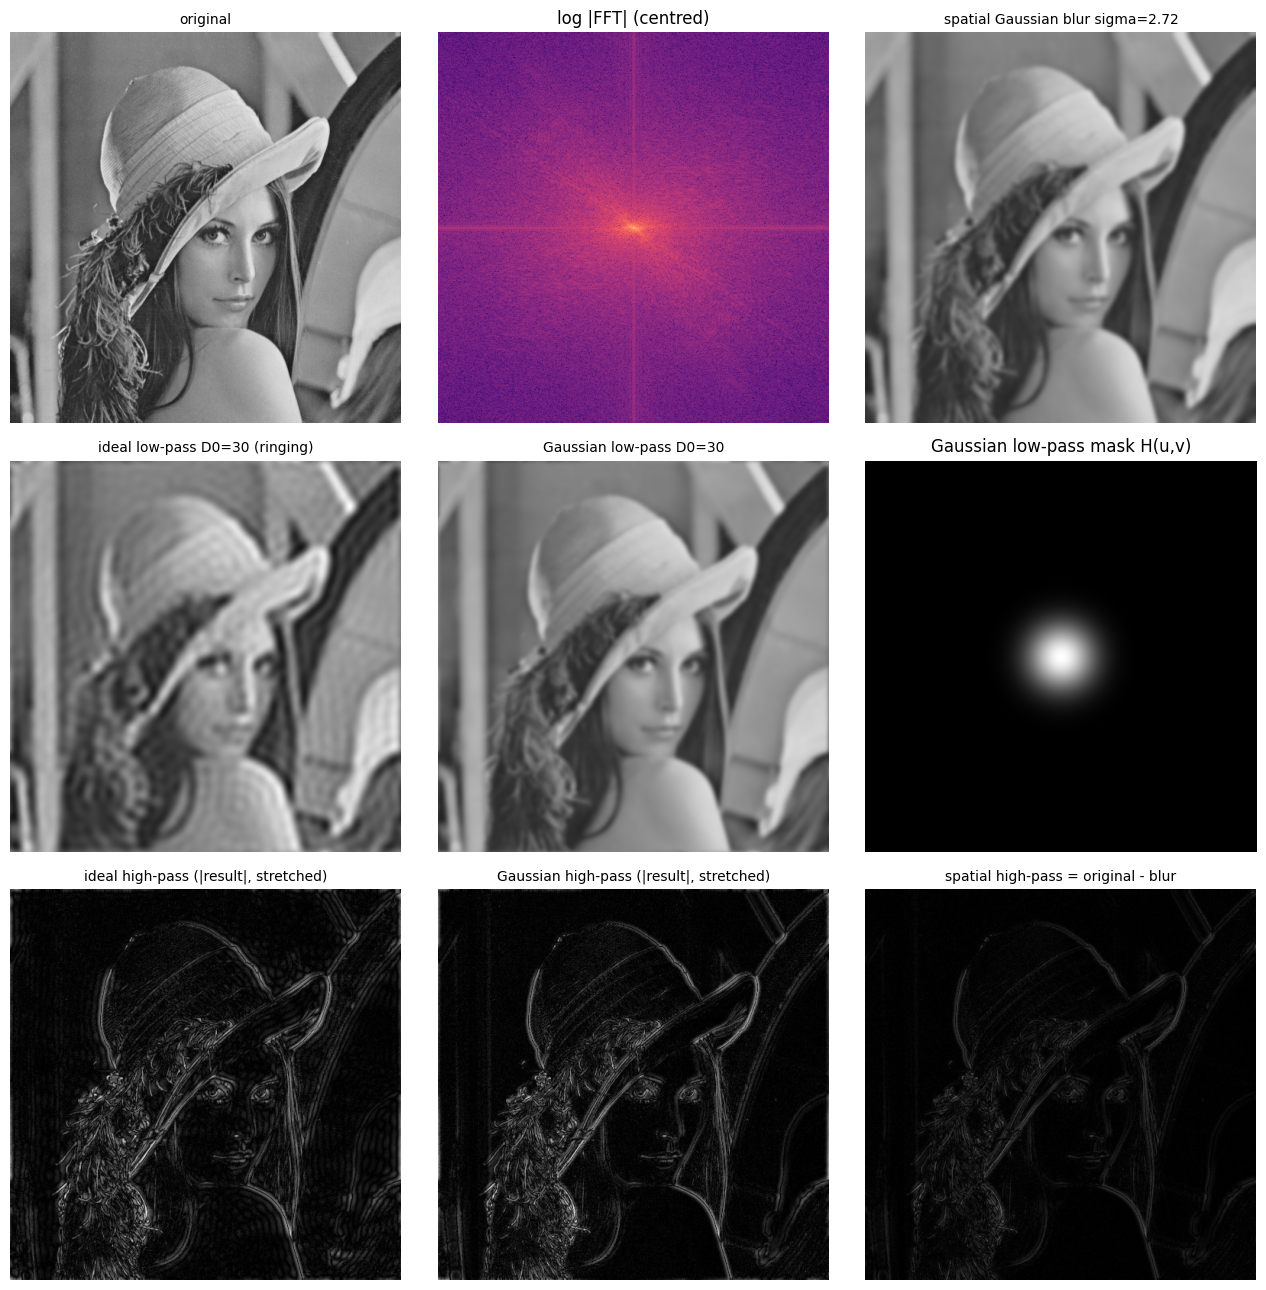

Gaussian low-pass (frequency) vs Gaussian blur (spatial, sigma=2.72): mean abs diff = 0.91, max = 68 grey levels, PSNR between them = 37.8 dB
PSNR vs original: ideal LP 24.79 dB, Gaussian LP 26.31 dB


In [9]:
D0 = 30
sigma_equiv = gray.shape[1] / (2 * np.pi * D0)

spectrum = fft_spectrum(gray)
ideal_lp = frequency_filter(gray, "lowpass", D0, "ideal")
gauss_lp = frequency_filter(gray, "lowpass", D0, "gaussian")
ideal_hp = frequency_filter(gray, "highpass", D0, "ideal")
gauss_hp = frequency_filter(gray, "highpass", D0, "gaussian")
spatial_blur = cv2.GaussianBlur(gray, (0, 0), sigma_equiv)        # spatial Gaussian with the equivalent sigma
mask_g = frequency_mask(gray.shape, "lowpass", D0, "gaussian")

fig, axes = plt.subplots(3, 3, figsize=(13, 13))
show(axes[0, 0], gray, "original")
axes[0, 1].imshow(spectrum, cmap="magma"); axes[0, 1].set_title("log |FFT| (centred)"); axes[0, 1].axis("off")
show(axes[0, 2], spatial_blur, f"spatial Gaussian blur sigma={sigma_equiv:.2f}")
show(axes[1, 0], ideal_lp, f"ideal low-pass D0={D0} (ringing)")
show(axes[1, 1], gauss_lp, f"Gaussian low-pass D0={D0}")
axes[1, 2].imshow(mask_g, cmap="gray"); axes[1, 2].set_title("Gaussian low-pass mask H(u,v)"); axes[1, 2].axis("off")
show(axes[2, 0], ideal_hp, "ideal high-pass (|result|, stretched)")
show(axes[2, 1], gauss_hp, "Gaussian high-pass (|result|, stretched)")
show(axes[2, 2], cv2.convertScaleAbs(gray.astype(np.int16) - spatial_blur.astype(np.int16)), "spatial high-pass = original - blur")
plt.tight_layout()
plt.savefig(OUT / "fft_filtering.png", dpi=120, bbox_inches="tight")
plt.show()

diff_lp = np.abs(gauss_lp.astype(float) - spatial_blur.astype(float))
print(f"Gaussian low-pass (frequency) vs Gaussian blur (spatial, sigma={sigma_equiv:.2f}): mean abs diff = {diff_lp.mean():.2f}, max = {diff_lp.max():.0f} grey levels, PSNR between them = {psnr(spatial_blur, gauss_lp):.1f} dB")
print(f"PSNR vs original: ideal LP {psnr(gray, ideal_lp):.2f} dB, Gaussian LP {psnr(gray, gauss_lp):.2f} dB")

### Bonus: low-pass filtering as a denoiser
Because noise lives mostly at high frequencies, a low-pass removes it - at the price of blurring. (The grey version of the noisy image already starts at a higher PSNR than the colour one, because averaging the 3 colour channels averages their independent noise.)

In [10]:
noisy_g = cv2.cvtColor(noisy["Gaussian noise (sigma=25)"], cv2.COLOR_BGR2GRAY)
fft_rows = [{"image": "noisy gray (Gaussian noise)", "PSNR (dB)": psnr(gray, noisy_g)}]
for D in [20, 40, 60, 90]:
    fft_rows.append({"image": f"Gaussian low-pass D0={D}", "PSNR (dB)": psnr(gray, frequency_filter(noisy_g, "lowpass", D, "gaussian"))})
fft_rows.append({"image": "spatial Gaussian blur sigma=1.0", "PSNR (dB)": psnr(gray, cv2.GaussianBlur(noisy_g, (5, 5), 1.0))})
fft_table = pd.DataFrame(fft_rows).round(2)
display(fft_table)

,image,PSNR (dB)
0,noisy gray (Gaussian noise),23.92
1,Gaussian low-pass D0=20,24.24
2,Gaussian low-pass D0=40,27.48
3,Gaussian low-pass D0=60,29.41
4,Gaussian low-pass D0=90,30.53
5,spatial Gaussian blur sigma=1.0,30.74


In [11]:
# Save all key numbers of notebook 02 for the report
update_results(RESULTS_JSON, "task1_2_filtering", {
    "description": "Denoising of lena.jpg with synthetic noise; PSNR/SSIM against the clean image.",
    "noise_settings": {"gaussian": "sigma=25, seed=0", "salt_pepper": "amount=5%, seed=0"},
    "filter_settings": FILTERS,
    "metrics_table": metrics.to_dict(orient="records"),
    "best_filter_per_noise": best,
    "sobel_magnitude": {"min": g["magnitude"].min(), "max": g["magnitude"].max(), "mean": g["magnitude"].mean()},
    "canny_edge_pixel_counts": canny_counts,
    "convolution_from_scratch": conv_table.to_dict(orient="records"),
    "fft": {"D0": D0, "equivalent_spatial_sigma": sigma_equiv,
            "gaussian_lowpass_vs_spatial_gaussian": {"mean_abs_diff": diff_lp.mean(), "max_abs_diff": diff_lp.max(), "psnr_db": psnr(spatial_blur, gauss_lp)},
            "psnr_vs_original_db": {"ideal_lowpass": psnr(gray, ideal_lp), "gaussian_lowpass": psnr(gray, gauss_lp)},
            "lowpass_denoising_table": fft_table.to_dict(orient="records")},
})
print("results saved")

results saved


## Summary / Observations

**Denoising (PSNR / SSIM against the clean image, see `outputs/filter_metrics.csv`)**

| noise | noisy | box 5x5 | Gaussian 5x5 | median 5x5 | bilateral |
|---|---|---|---|---|---|
| Gaussian sigma=25 | 20.36 dB / 0.296 | 28.19 / 0.730 | 28.94 / 0.703 | 28.07 / 0.685 | **29.10 / 0.703** |
| Salt & pepper 5 % | 18.21 dB / 0.338 | 27.21 / 0.685 | 27.20 / 0.647 | **30.89 / 0.856** | 18.27 / 0.299 |

* **Gaussian noise:** all four filters gain 8-9 dB and are within about 1 dB of each other. Bilateral (29.10 dB) and Gaussian (28.94 dB) are the best by PSNR, the box filter is best by SSIM (0.730). This is expected: Gaussian noise is independent per pixel and zero-mean, so averaging neighbours reduces its variance. The edge-preserving bilateral filter has a small advantage because it blurs the edges less. The differences between the four are small, so with other parameters the order could change.
* **Salt & pepper noise:** the **median filter is clearly the winner** (30.89 dB, SSIM 0.856, +12.7 dB). The impulses are extreme outliers: the mean (box/Gaussian) spreads them into grey blotches (27.2 dB), while the median simply discards them. The **bilateral filter fails (18.27 dB, almost no improvement)**: an impulse pixel differs so much in intensity from its neighbours that they receive almost zero weight, so the pixel keeps its own value.
* **Gradients:** Sobel Gx responds to vertical edges and Gy to horizontal ones; the gradient magnitude on lena ranges from 0 to 713 (mean 49.1). The Laplacian shows the same edges as thin double lines but amplifies fine texture and noise more.
* **Canny:** on the clean image the number of edge pixels drops from 28 957 (thresholds 50/100) to 15 911 (100/200) and 10 885 (150/300) - higher thresholds keep only the strong edges. On the Gaussian-noise image Canny **without blur gives 56 373 mostly false edge pixels**; blurring first (sigma 1.5) reduces this to 5 199 and the main contours (hat, face, shoulder) reappear. Too much blur (sigma 3) leaves only 901 pixels and real edges are lost, so sigma is a trade-off.
* **From-scratch convolution:** `convolve2d_from_scratch` is identical to `cv2.filter2D` in floating point (max absolute difference 0.0 for box, Gaussian and Sobel kernels); after rounding to uint8 the largest difference is 1 grey level (Gaussian kernel, OpenCV rounding).
* **Frequency domain:** the spectrum is concentrated around the centre (low frequencies) with bright horizontal/vertical lines from the image border/edges. The *ideal* low-pass shows visible **ringing** (ripples around edges, PSNR 24.79 dB vs original) while the *Gaussian* low-pass is smooth (26.31 dB). A Gaussian low-pass with D0 = 30 matches a spatial Gaussian blur with sigma = 2.72 (mean absolute difference 0.91 grey levels, PSNR between the two 37.8 dB; the maximum difference of 68 is at the image border, because the FFT treats the image as periodic). High-pass images keep only edges/texture. As a denoiser on the grey noisy image, a Gaussian low-pass improves PSNR from 23.92 dB (noisy) to 30.53 dB (D0 = 90); a 5x5 spatial Gaussian (sigma 1) gives 30.74 dB - both do the same job.
* **Limitation:** all parameters (kernel size, sigma, thresholds) were fixed by hand, not optimised per filter; with a different kernel size the ranking of the Gaussian-noise filters could change.